In [130]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import sqlite3

In [131]:
# 1) connect dataset 

In [132]:
con=sqlite3.connect(r"C:\Users\admin\Downloads\customer_churn.db")
sql_q="""select name from sqlite_master where type='table'"""

In [133]:
# sqlite_master=This is a special SQLite system table.
# It contains information about objects in your database, such as:
# tables
# indexes
# views
# triggers


# “I used SQLite's sqlite_master system table to retrieve the names of all tables dynamically, 
# so I didn't have to hard-code each table name in my Python code.

In [134]:
# SQL = language
# SQLite = database
# sqlite3 = Python connector for SQLite

In [135]:
# chose SQLite because the dataset was relatively small and this was a portfolio analytics project.
# SQLite is lightweight, requires no separate server setup, and was sufficient for my SQL analysis and Python integration.
# For a larger production system with multiple users and concurrent access, 
# I would use a server-based database such as MySQL or SQL Server.”

In [136]:
# 2) load dataset

In [137]:
tables = pd.read_sql(sql_q, con)

for i in tables['name']:          #loops run every table in the dataset 
    df=pd.read_sql(f"select * from {i}",con)
    globals()[f"df_{i}"]=df         #create variable with dynamic name 
    print(f"created dataframe:df_{i}")

con.close()
    

created dataframe:df_db_customer
created dataframe:df_db_subscription
created dataframe:df_db_support


In [138]:
df1=df_db_customer
df2=df_db_subscription
df3=df_db_support



In [139]:
# table 1===df1=df_db_customer
# 3) understand the data 

In [140]:
df1.head(10)

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,None,Delhi,Women,1988-12-10 00:00:00,None,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,None,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,None,None
8,0015-UOCOJ,maya,None,Kathmandu,Women,1985-07-07 00:00:00,None,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,None,None


In [141]:
df1.tail(10)

,customerid,name,country,state,gender,dob,interests,pincode
11,0017-IUDMW,rangadevi,India,Karnataka,Female,1981-06-18 00:00:00,None,None
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01 00:00:00,None,None
13,0019-EFAEP,raju,India,Meghalaya,Female,1992-04-25 00:00:00,None,None
14,0019-GFNTW,Madhav,India,Uttar Pradesh,Men,1979-11-11 00:00:00,None,None
15,0020-INWCK,parvati,India,Delhi,Female,1986-02-28 00:00:00,job,None
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,None,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,None,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,None,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,None,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,None,None


In [142]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     object
 1   name        21 non-null     object
 2   country     18 non-null     object
 3   state       21 non-null     object
 4   gender      21 non-null     object
 5   dob         21 non-null     object
 6   interests   4 non-null      object
 7   pincode     0 non-null      object
dtypes: object(8)
memory usage: 1.4+ KB


In [143]:
df1.describe()


,customerid,name,country,state,gender,dob,interests,pincode
count,21,21,18,21,21,21,4,0
unique,21,21,2,9,4,21,4,0
top,0002-ORFBO,keshav,India,Delhi,Female,1982-04-12 00:00:00,travel,NaN
freq,1,1,17,4,9,1,1,NaN


In [144]:
# 4)  clean the data

In [145]:
# during observation i can see:
    # 1) pincode coloumn is null so we can drop this
    # 2) rename name to customer_name
    # 3) data standarization on gender coloum
    # 4) type casting on dob

In [146]:
df1.drop("pincode",axis = 1,inplace=True)

In [147]:
df1

,customerid,name,country,state,gender,dob,interests
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama
5,0013-MHZWF,durga,None,Delhi,Women,1988-12-10 00:00:00,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,None
8,0015-UOCOJ,maya,None,Kathmandu,Women,1985-07-07 00:00:00,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,None


In [148]:
# we can also drop using index
# df1.drop(df1.coloums[-1:],axis=1)

# drop is used to delete value either in row-wise or the column-wise
# del is used to delete by only column-wise

In [149]:
df1.rename(columns={"name": "customer_name"}, inplace=True)

In [150]:
df1.columns

Index(['customerid', 'customer_name', 'country', 'state', 'gender', 'dob',
       'interests'],
      dtype='object')

In [151]:
df1["gender"]=df1["gender"].replace("Women","Female")

In [152]:
df1["gender"]=df1["gender"].replace("Men","Male")

In [153]:
df1["gender"]

0       Male
1       Male
2     Female
3       Male
4     Female
5     Female
6     Female
7       Male
8     Female
9       Male
10      Male
11    Female
12    Female
13    Female
14      Male
15    Female
16    Female
17    Female
18      Male
19      Male
20    Female
Name: gender, dtype: object

In [154]:
df1["dob"] = pd.to_datetime(df1["dob"])

In [155]:
# 5) handle missing value

In [156]:
df1.isna().sum()

customerid        0
customer_name     0
country           3
state             0
gender            0
dob               0
interests        17
dtype: int64

In [157]:
df1[df1['country'].isna()]

,customerid,customer_name,country,state,gender,dob,interests
5,0013-MHZWF,durga,None,Delhi,Female,1988-12-10,None
8,0015-UOCOJ,maya,None,Kathmandu,Female,1985-07-07,None
12,0018-NYROU,chitra,None,Telangana,Female,2004-12-01,None


In [158]:
# df1["country"] = df1["country"].fillna(df1["country"].mode()[0]) this is not work here bcz we have state so we can find the value using this state

In [159]:
country_dict = df1["country"].value_counts().to_dict()
print(country_dict)

{'India': 17, 'Nepal': 1}


In [160]:
# fill misiing values using the state coloum

In [161]:
#Remove only those rows where country is missing (NaN),set index used to create specific coloum as a index 
state_map = df1.dropna(subset=["country"]).set_index("state")["country"].to_dict()
print(state_map)

df1['country']=df1["country"].fillna(df1["state"].map(state_map))
df1['country']

{'Maharashtra': 'India', 'Karnataka': 'India', 'Delhi': 'India', 'Nagaland': 'India', 'Meghalaya': 'India', 'Rajasthan': 'India', 'Kathmandu': 'Nepal', 'Uttar Pradesh': 'India', 'Telangana': 'India'}


0     India
1     India
2     India
3     India
4     India
5     India
6     India
7     India
8     Nepal
9     Nepal
10    India
11    India
12    India
13    India
14    India
15    India
16    India
17    India
18    India
19    India
20    India
Name: country, dtype: object

In [162]:
# table 2 created dataframe:df_db_subscription

In [163]:
# understand the data

In [164]:
df2.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [165]:
df2.tail()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
16,0020-JDNXP,2022-01-19,Organic,2024-01-19,Premium,Annual,None,None,20.99,550,62
17,0021-IKXGC,2021-07-07,Paid,2025-07-07,Standard,Annual,None,None,13.99,840,27
18,0022-TCJCI,2023-09-14,Refferal,2024-09-14,Basic,Monthly,2024-09-14,Forgot to cancel trial,16.99,42,99
19,0023-HGHWL,2020-06-23,Organic,2025-06-23,Premium,Annual,None,None,22.99,1955,7
20,0023-UYUPN,2022-12-31,Paid,2025-12-31,Standard,Monthly,None,None,13.99,790,47


In [166]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     object 
 1   subscription_start_date  21 non-null     object 
 2   subscription_type        21 non-null     object 
 3   renewal_date             21 non-null     object 
 4   plan_type                21 non-null     object 
 5   contract_type            21 non-null     object 
 6   cancellation_date        6 non-null      object 
 7   cancellation_reason      6 non-null      object 
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.9+ KB


In [167]:
#  clean the data
   # 1) type  casting

In [168]:
df2["subscription_start_date"]=pd.to_datetime(df2["subscription_start_date"])
df2["renewal_date"]=pd.to_datetime(df2["renewal_date"])
df2["cancellation_date"]=pd.to_datetime(df2["cancellation_date"])

In [169]:
data=["subscription_start_date","renewal_date" ,"cancellation_date"]
df2[data].apply(pd.to_datetime)

,subscription_start_date,renewal_date,cancellation_date
0,2021-03-15,2025-03-15,NaT
1,2020-08-01,2024-08-01,2024-09-10
2,2022-11-20,2025-11-20,NaT
3,2019-05-10,2025-05-10,NaT
4,2023-01-05,2024-01-05,2024-02-28
5,2022-06-18,2025-06-18,NaT
6,2021-09-30,2024-09-30,2024-11-15
7,2020-02-14,2025-02-14,NaT
8,2023-07-22,2024-07-22,NaT
9,2022-04-03,2025-04-03,NaT


In [170]:
# table 3 ==df3=df_db_support

In [171]:
df3.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None


In [172]:
df3.tail()


,customerid,complaint_date,escalations,csat_score,col_1,comment
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None
5,0017-IUDMW,2024-04-10 00:00:00,Y,25,None,None
6,0019-EFAEP,2024-09-27 00:00:00,Y,30,None,None
7,0022-TCJCI,2024-09-13 00:00:00,Y,10,None,None
8,0022-TCJCI,2024-09-14 00:00:00,N,90,None,received refund


In [173]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      object
 1   complaint_date  9 non-null      object
 2   escalations     9 non-null      object
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      object
dtypes: int64(1), object(5)
memory usage: 564.0+ bytes


In [174]:
df3.drop("col_1" ,axis=1 ,inplace=True)
df3.columns

Index(['customerid', 'complaint_date', 'escalations', 'csat_score', 'comment'], dtype='object')

In [175]:
df3["complaint_date"]=pd.to_datetime(df3["complaint_date"])
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      object        
 1   complaint_date  9 non-null      datetime64[ns]
 2   escalations     9 non-null      object        
 3   csat_score      9 non-null      int64         
 4   comment         4 non-null      object        
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 492.0+ bytes


In [176]:
# FEATURE ENGINERRING AND DATA ANALYSIS 

In [177]:
df2.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [178]:
# now we crete a new columns ...customer churn or not ...using the cancellation date bcxz cancelation date is tehre means user churn out
df2["churn_flag"]=np.where(df2["cancellation_date"].notna(),1,0)
df2.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [179]:
df=(df2.merge(df1,on="customerid",how="left").merge(df3,on="customerid" ,how="left"))
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,interests,complaint_date,escalations,csat_score,comment
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,travel,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,None,2024-08-28,N,60.0,service issue
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,None,2024-08-28,Y,10.0,demaned refund
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,lalita,India,Delhi,Female,1978-02-15,movie,NaT,NaN,NaN,NaN
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,mohan,India,Nagaland,Male,2001-08-30,None,NaT,NaN,NaN,NaN
5,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,mira,India,Delhi,Female,1990-05-05,drama,2024-01-20,Y,20.0,None
6,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,None,17.99,720,...,durga,India,Delhi,Female,1988-12-10,None,2025-03-18,N,90.0,guidance to renew
7,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,mina,India,Meghalaya,Female,1976-09-21,None,2024-11-01,N,30.0,None
8,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,None,22.99,1840,...,madan,India,Rajasthan,Male,1999-03-14,None,NaT,NaN,NaN,NaN
9,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,None,13.99,240,...,maya,Nepal,Kathmandu,Female,1985-07-07,None,NaT,NaN,NaN,NaN


In [180]:
df=(df2.merge(df1,on="customerid",how="left").merge(df3,on="customerid" ,how="left"))
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,interests,complaint_date,escalations,csat_score,comment
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,travel,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,None,2024-08-28,N,60.0,service issue
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,None,2024-08-28,Y,10.0,demaned refund
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,lalita,India,Delhi,Female,1978-02-15,movie,NaT,NaN,NaN,NaN
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,mohan,India,Nagaland,Male,2001-08-30,None,NaT,NaN,NaN,NaN
5,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,mira,India,Delhi,Female,1990-05-05,drama,2024-01-20,Y,20.0,None
6,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,None,17.99,720,...,durga,India,Delhi,Female,1988-12-10,None,2025-03-18,N,90.0,guidance to renew
7,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,mina,India,Meghalaya,Female,1976-09-21,None,2024-11-01,N,30.0,None
8,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,None,22.99,1840,...,madan,India,Rajasthan,Male,1999-03-14,None,NaT,NaN,NaN,NaN
9,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,None,13.99,240,...,maya,Nepal,Kathmandu,Female,1985-07-07,None,NaT,NaN,NaN,NaN


In [181]:
#  every time  you will check shape of final dataset and the shape of that dataframe which we are used in join .....herer we used df2

In [182]:
df2.shape          
# we can left join on df2 table there total rows is 21 but our final df rows is 23 so something is wrong to join

(21, 12)

In [183]:
df.shape

(23, 22)

In [184]:
df2["customerid"].nunique()

21

In [185]:
df1["customerid"].nunique()

21

In [186]:
df3["customerid"].nunique()

7

In [187]:
df3["customerid"].shape

(9,)

In [188]:
# In support table there is duplicate customer_id...so this is main resoun row was increses on final dataset
# so we create new column an that df3 and perform the groupby
# we also drop the duplicated coloum using customerid ...bbut first sort  by value 

In [189]:
df3["complaint_count"]=df3.groupby("customerid")["customerid"].transform("count")

In [190]:
df3=df3.sort_values("complaint_date").drop_duplicates("customerid",keep="last")
df3

,customerid,complaint_date,escalations,csat_score,comment,complaint_count
2,0013-EXCHZ,2024-01-20,Y,20,None,1
5,0017-IUDMW,2024-04-10,Y,25,None,1
1,0003-MKNFE,2024-08-28,Y,10,demaned refund,2
8,0022-TCJCI,2024-09-14,N,90,received refund,2
6,0019-EFAEP,2024-09-27,Y,30,None,1
4,0013-SMEOE,2024-11-01,N,30,None,1
3,0013-MHZWF,2025-03-18,N,90,guidance to renew,1


In [191]:
# merge again after handling groping and handling duplicate......groping bcz we neet to keep record about complaint so now data store in complaint_count
df=(df2.merge(df1,on="customerid",how="left").merge(df3,on="customerid" ,how="left"))
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,interests,complaint_date,escalations,csat_score,comment,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,India,Maharashtra,Male,1982-04-12,travel,NaT,NaN,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,India,Karnataka,Male,1995-11-23,None,2024-08-28,Y,10.0,demaned refund,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,India,Delhi,Female,1978-02-15,movie,NaT,NaN,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,India,Nagaland,Male,2001-08-30,None,NaT,NaN,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,India,Delhi,Female,1990-05-05,drama,2024-01-20,Y,20.0,None,1.0
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,None,17.99,720,...,India,Delhi,Female,1988-12-10,None,2025-03-18,N,90.0,guidance to renew,1.0
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,India,Meghalaya,Female,1976-09-21,None,2024-11-01,N,30.0,None,1.0
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,None,22.99,1840,...,India,Rajasthan,Male,1999-03-14,None,NaT,NaN,NaN,NaN,NaN
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,None,13.99,240,...,Nepal,Kathmandu,Female,1985-07-07,None,NaT,NaN,NaN,NaN,NaN
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,None,6.99,335,...,Nepal,Kathmandu,Male,1993-10-29,None,NaT,NaN,NaN,NaN,NaN


In [192]:
df.shape

(21, 23)

In [193]:
df2.shape

(21, 12)

In [194]:

df["complaint_count"]=df["complaint_count"].fillna(0)
df


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,interests,complaint_date,escalations,csat_score,comment,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,India,Maharashtra,Male,1982-04-12,travel,NaT,NaN,NaN,NaN,0.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,India,Karnataka,Male,1995-11-23,None,2024-08-28,Y,10.0,demaned refund,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,India,Delhi,Female,1978-02-15,movie,NaT,NaN,NaN,NaN,0.0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,India,Nagaland,Male,2001-08-30,None,NaT,NaN,NaN,NaN,0.0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,India,Delhi,Female,1990-05-05,drama,2024-01-20,Y,20.0,None,1.0
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,None,17.99,720,...,India,Delhi,Female,1988-12-10,None,2025-03-18,N,90.0,guidance to renew,1.0
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,...,India,Meghalaya,Female,1976-09-21,None,2024-11-01,N,30.0,None,1.0
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,None,22.99,1840,...,India,Rajasthan,Male,1999-03-14,None,NaT,NaN,NaN,NaN,0.0
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,None,13.99,240,...,Nepal,Kathmandu,Female,1985-07-07,None,NaT,NaN,NaN,NaN,0.0
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,None,6.99,335,...,Nepal,Kathmandu,Male,1993-10-29,None,NaT,NaN,NaN,NaN,0.0


In [195]:
df.to_csv("churn.csv",index=False)

In [196]:
import os

os.getcwd()

'C:\\Users\\admin'

In [197]:
# data analysis

In [198]:
df.shape

(21, 23)

In [199]:
df["churn_flag"].mean()
# if you want to in percentage then multiply by 100
rate=df["churn_flag"].mean()*100
print("churn rate is:",round(rate,2),"%")

churn rate is: 28.57 %


In [200]:
# churn by plan type 

In [201]:
# mul are used to convert in the percentage 
plan_typ=df.groupby("plan_type")["churn_flag"].mean().mul(100).reset_index(name="churn_rate_pct")
print(plan_typ)


  plan_type  churn_rate_pct
0     Basic       60.000000
1   Premium       14.285714
2  Standard       22.222222


In [202]:
# churn by state +sum(revenue)+count of user
plan_stat=df.groupby("state")["churn_flag"].mean().mul(100).reset_index()
print(plan_stat) 
#all the people churn from karnatka and mmost of people churn from meghalaya

           state  churn_flag
0          Delhi   25.000000
1      Karnataka  100.000000
2      Kathmandu    0.000000
3    Maharashtra    0.000000
4      Meghalaya   66.666667
5       Nagaland    0.000000
6      Rajasthan    0.000000
7      Telangana   50.000000
8  Uttar Pradesh    0.000000


In [203]:
# chuen from the subscription  type
plan_subscription=df.groupby("subscription_type")["churn_flag"].mean().mul(100).reset_index()
print

<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [204]:
# ARPU-average revenue per user
arpu=df["monthly_charges"].mean()
print(arpu)



18.847142857142856


In [205]:
# avg custermor tenure(how many time customer stay with us)
today=pd.Timestamp.today()
df["tenure"]=np.where(df["cancellation_date"].notna(),
         (df["cancellation_date"]-df["subscription_start_date"]).dt.days,
         (today-df["subscription_start_date"]).dt.days
        )

avg_tenure=df["tenure"].mean()
print("avg tenure is",round(avg_tenure))





avg tenure is 1554


In [206]:
# revenue at risk/lost when churn user
revenue_at_risk=df.loc[df["churn_flag"]==1,"monthly_charges"].sum()
print(revenue_at_risk)

73.94


In [207]:
# iscalation rate(problem not solved)
iscalation_rate=(df["escalations"]=="Y").mean()*100
print(iscalation_rate)

19.047619047619047


In [208]:
# avg complaint per user
df["complaint_count"].sum()/ df["customerid"].nunique()

0.42857142857142855

In [209]:
# change yes to 1 and no to 0 so we finf corelation

df["escalations"] = np.where(
    df["escalations"] == "Y",1, 0)


In [210]:
# find correlation

# Correlation tells us how strongly two variables are related to each other


# corr_df = df[["escalations", "churn_flag"]].dropna()
correlation=df["escalations"].corr(df["churn_flag"])
print(correlation)


0.7669649888473702


In [211]:
# Correlation usually ranges from -1 to +1:

# Correlation	Meaning
# +1	Perfect positive relationship
# +0.7	Strong positive relationship
# +0.3	Weak/moderate positive relationship
# 0	No linear relationship
# -0.3	Weak/moderate negative relationship
# -0.7	Strong negative relationship
# -1	Perfect negative relationship

In [212]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'interests', 'complaint_date', 'escalations', 'csat_score', 'comment',
       'complaint_count', 'tenure'],
      dtype='object')

In [213]:
# visulization using matplotleab 

In [214]:
dfv = df.copy()
dfv.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,state,gender,dob,interests,complaint_date,escalations,csat_score,comment,complaint_count,tenure
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,Maharashtra,Male,1982-04-12,travel,NaT,0,NaN,NaN,0.0,2030.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,Karnataka,Male,1995-11-23,None,2024-08-28,1,10.0,demaned refund,2.0,1501.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,Delhi,Female,1978-02-15,movie,NaT,0,NaN,NaN,0.0,1415.0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,Nagaland,Male,2001-08-30,None,NaT,0,NaN,NaN,0.0,2705.0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,Delhi,Female,1990-05-05,drama,2024-01-20,1,20.0,None,1.0,419.0


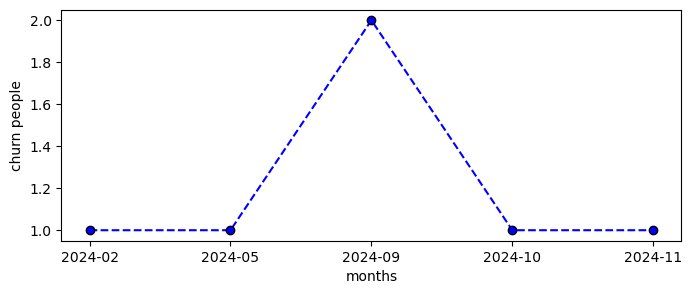

In [215]:
# monthly churn trend(time series kpi)(kitne log monthly chodkar gaye )


dfv['cancellation_month']=dfv['cancellation_date'].dt.to_period('M')
trend = dfv[dfv['churn_flag']==1].groupby('cancellation_month').size()


plt.figure(figsize=(8,3))
plt.plot(trend.index.astype(str) ,trend.values,marker="o",color="blue",linestyle="dashed",markeredgecolor="black")
plt.xlabel("months")
plt.ylabel("churn people")
plt.show()


# convert cancellation date into month
# then group all the churn employee based on month
 




<BarContainer object of 3 artists>

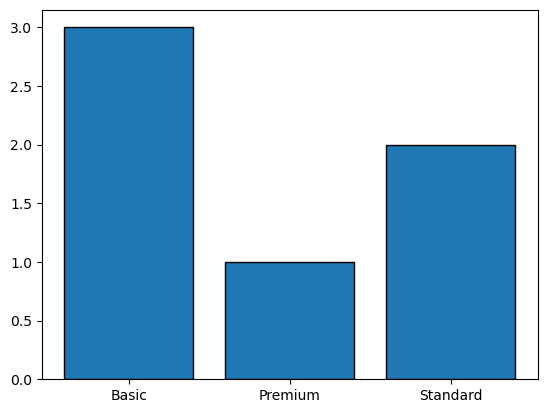

In [216]:
# churn by plan type
dfv.head()
plntype = df.groupby('plan_type')['churn_flag'].sum()
plntype
plt.bar(plntype.index,plntype.values,edgecolor="black")

# group by plann type and show how many people churn

<BarContainer object of 9 artists>

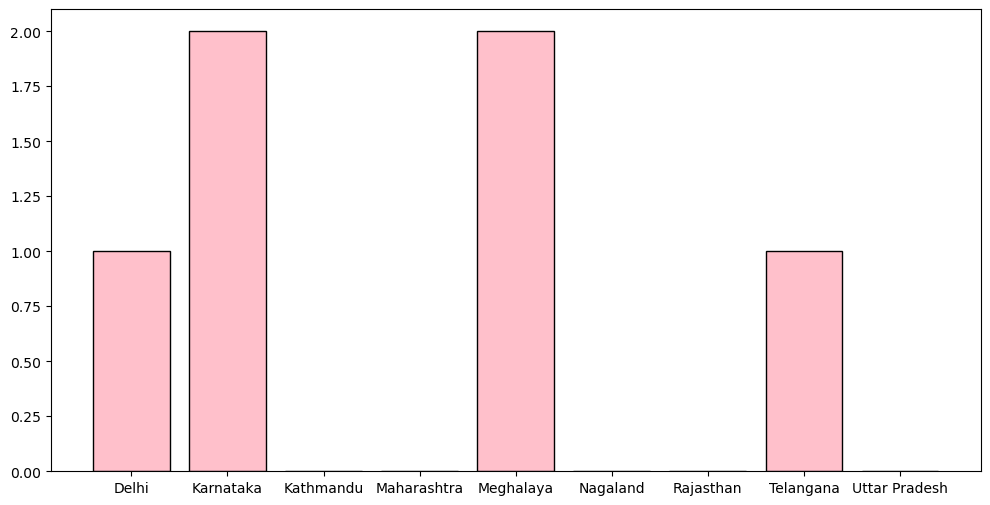

In [217]:
# churn by state
plt.figure(figsize=(12,6))
plntype = df.groupby('state')['churn_flag'].sum()
plntype
plt.bar(plntype.index,plntype.values,edgecolor="black",color='pink')

In [218]:
import warnings
warnings.filterwarnings("ignore")
#  its used to fiter out all the warning 

In [219]:
# encoding = convert category to numerical value    bcz correlation need to all the numerical value


df_encode = dfv[['plan_type', 'contract_type', 'churn_score' ,'churn_flag', 'escalations']]
cat_col = ['plan_type', 'contract_type']

for i in cat_col:
    df_encode[i] = df_encode[i].astype('category').cat.codes  

# .cat.codes =convert the number to the each category

<Axes: >

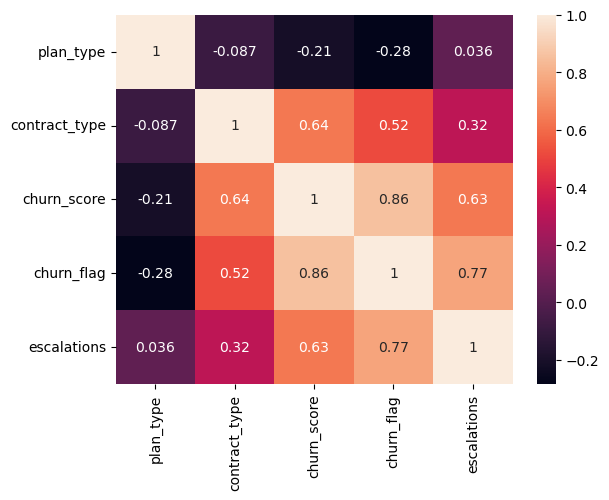

In [220]:
# visualization using seaborn
# heatmap(correlation matrix)

sns.heatmap(df_encode.corr(), annot=True)

In [221]:

# uses this method insted of above one bcz system randomly give numerical number like 1 is low etc. so use dectionary and tell what is first prefernce

df_encoded = dfv[['plan_type', 'contract_type', 'churn_score' ,'churn_flag', 'escalations']]

cat_cols = {'plan_type':{ 'Basic', 'Standard', 'Premium'},
    'contract_type':{ 'Monthly', 'Annual'}}

for i,j in cat_cols.items():
    
 df_encoded[i] = pd.Categorical(df_encoded[i],categories=j, ordered=True).codes

    
# Convert a categorical column into numerical values according to a specific order that you provide.
# .codes converts them into numbers.

<Axes: >

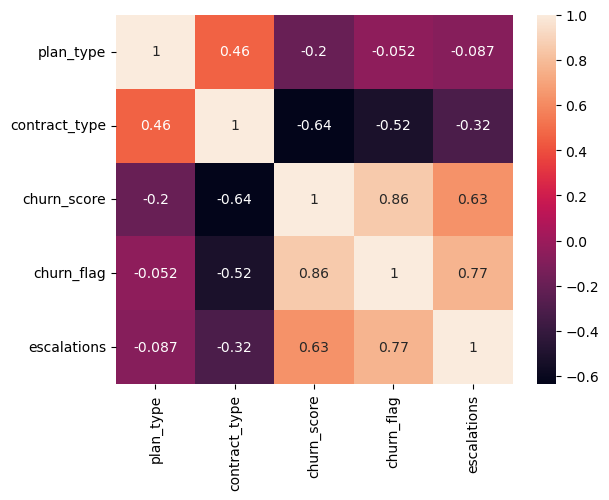

In [222]:
# its predict the correct value becoz there numerical convertion is correct
sns.heatmap(df_encoded.corr(), annot=True)

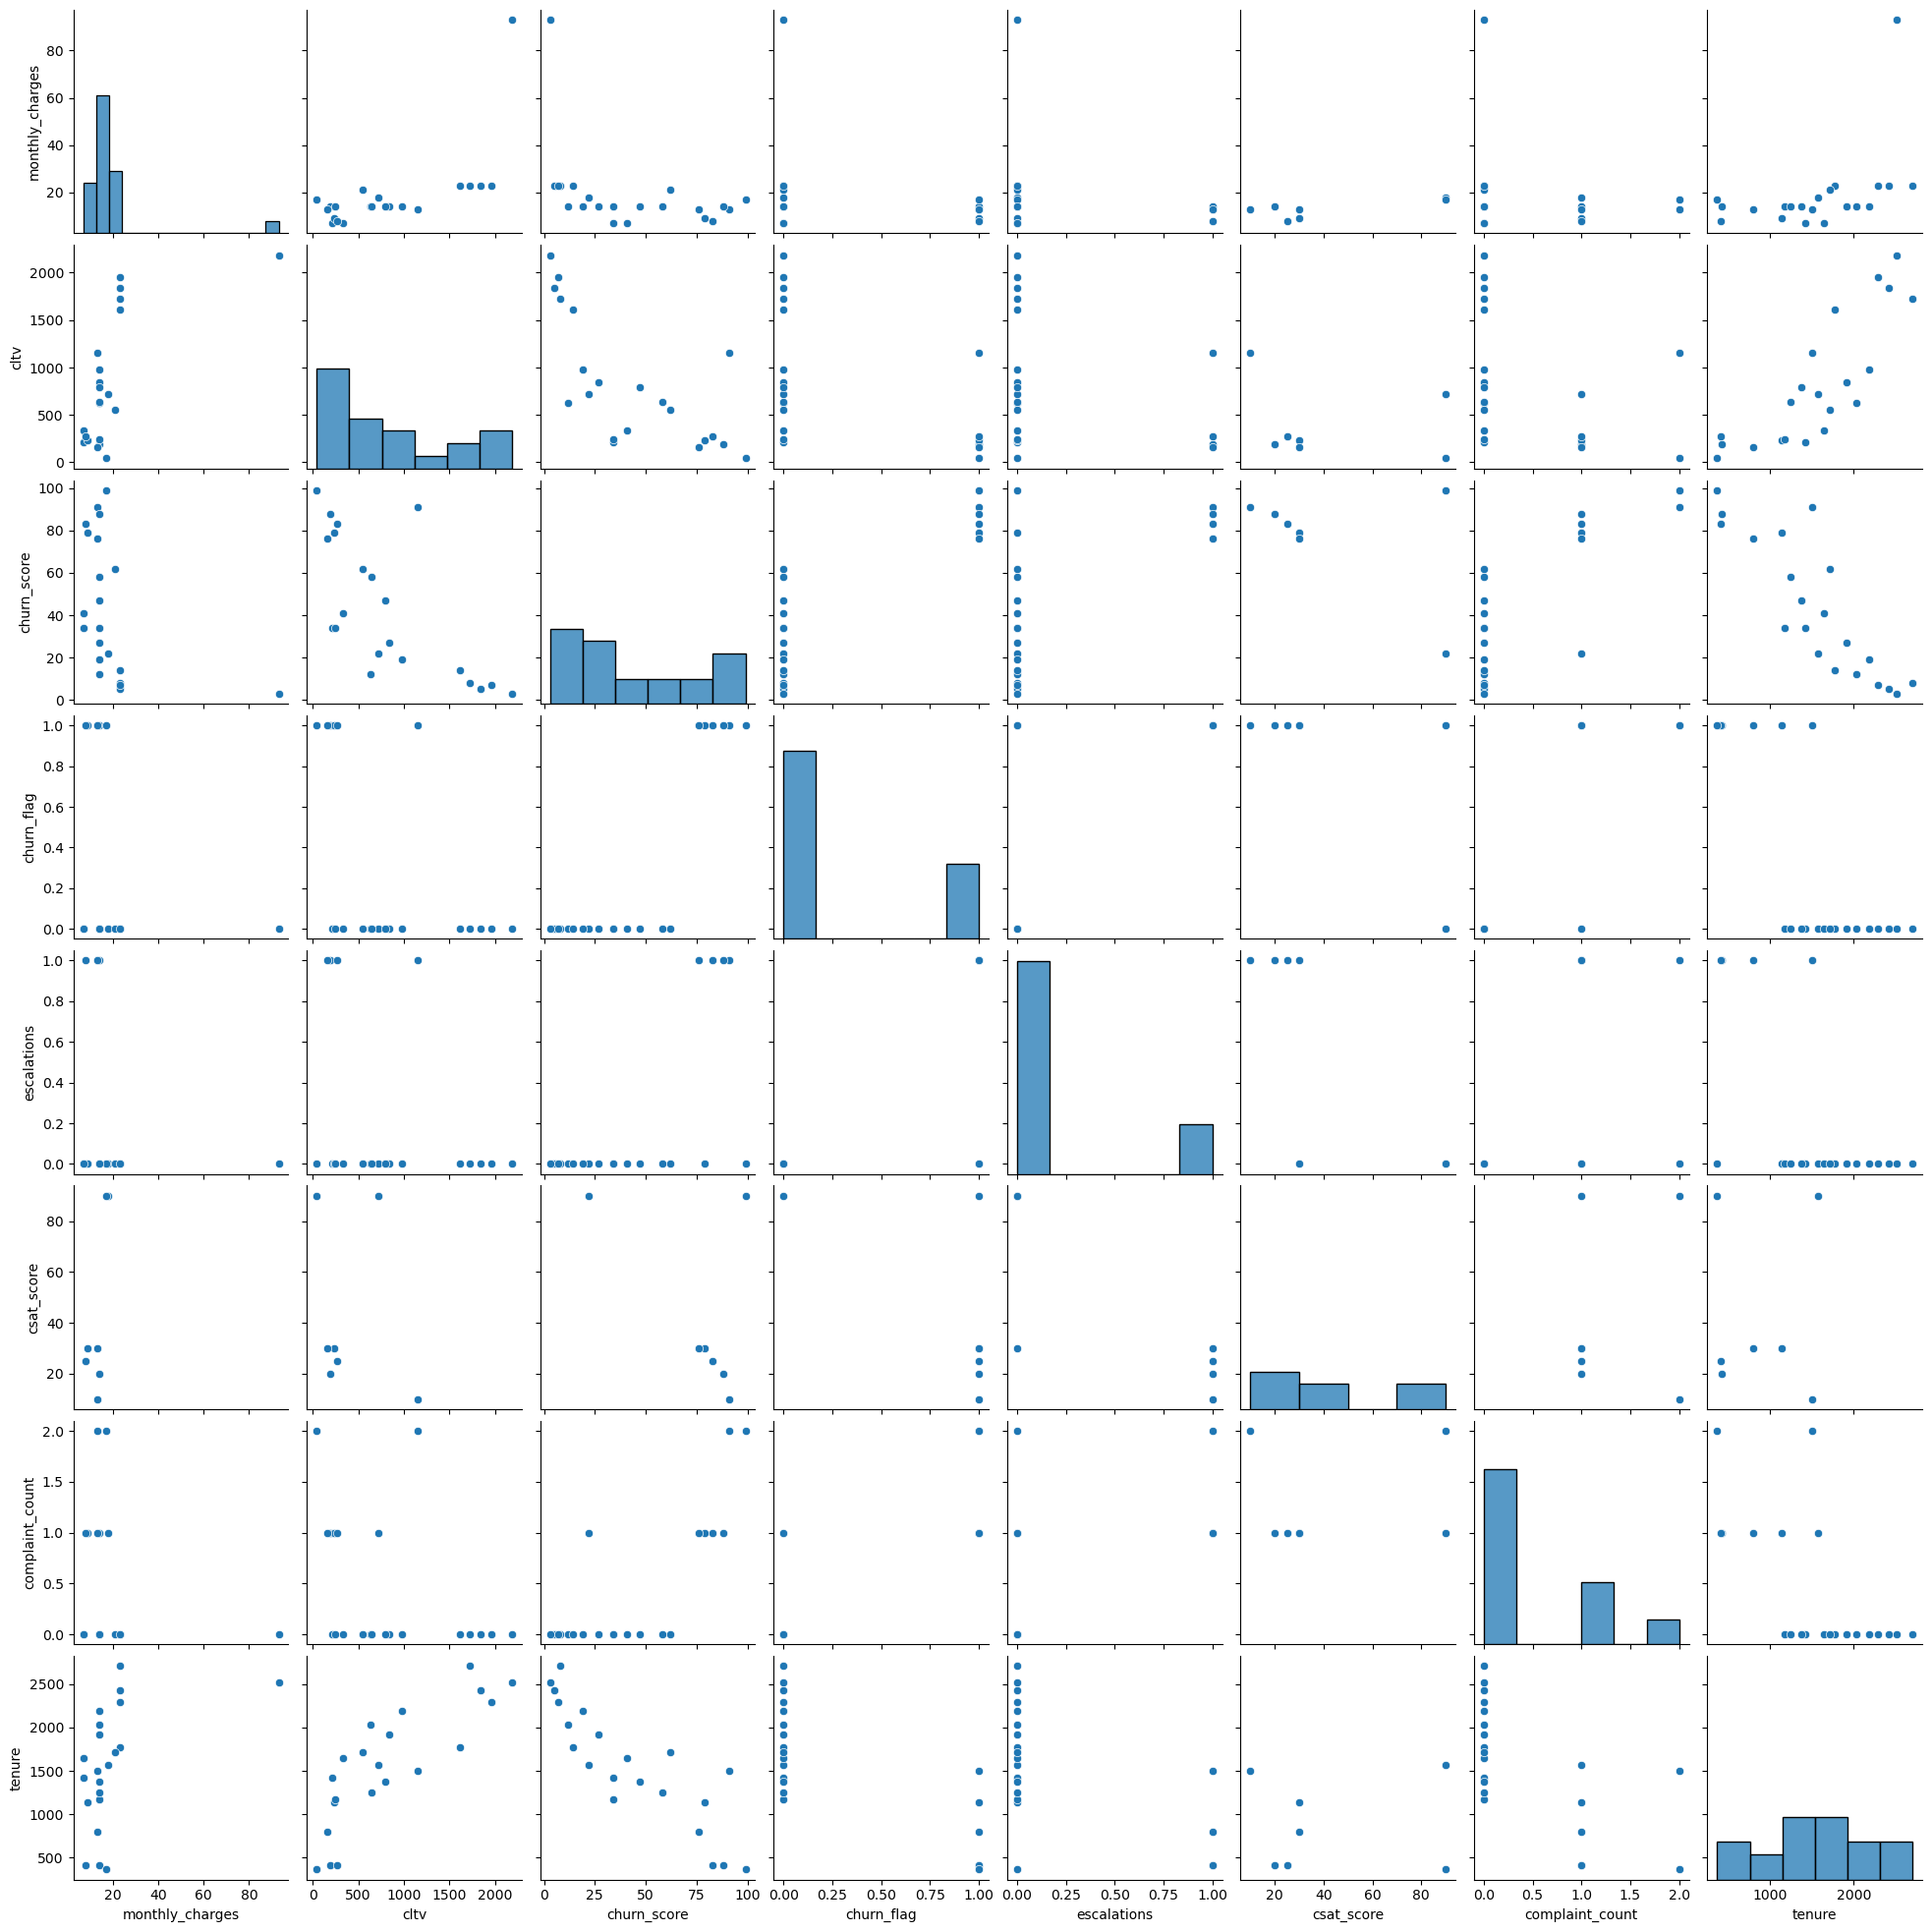

In [223]:
# pairplot(find relationship betweeb data)
sns.pairplot(dfv)



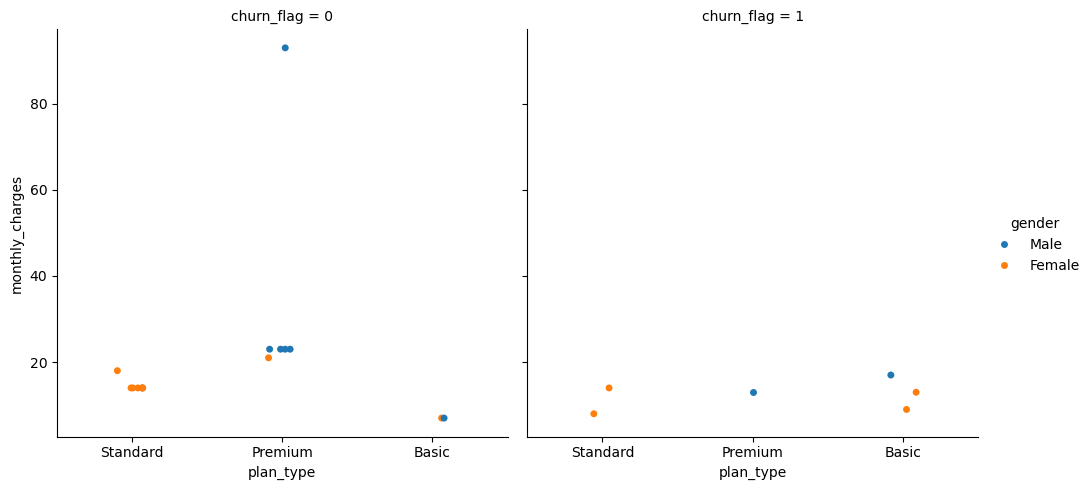

In [224]:
# catplot/facegrid plot  visualize the relationship between categorical variables and numerical variables.

sns.catplot(
    data=dfv,
    x="plan_type",
    y="monthly_charges",
    hue="gender",
    col="churn_flag"
)

In [225]:
dfv.pivot_table(
    values="churn_flag",
    index="plan_type",
    aggfunc="mean"
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [226]:
summary = pd.pivot_table(
    dfv,
    index="plan_type",
    values=["monthly_charges", "customerid", "churn_flag"],
    aggfunc={
        "monthly_charges": "sum",
        "customerid": "nunique",
        "churn_flag": "mean"
    }
)
print(summary)

           churn_flag  customerid  monthly_charges
plan_type                                         
Basic        0.600000           5            52.95
Premium      0.142857           7           218.93
Standard     0.222222           9           123.91


In [228]:
# Connect to SQLite database
conn = sqlite3.connect('testt_database.sqlite')

#table details
conn.execute("CREATE TABLE users (first_name TEXT, country TEXT, budget INTEGER)")

# Commit / save changes
conn.commit()


In [230]:
# Create cursor
cursor = conn.cursor()

# Insert data
cursor.execute("""
INSERT INTO users (first_name, country, budget)
VALUES
('Madhav', 'India', 5000),
('Rishabh', 'Germany', 2500),
('Vishakha', 'India', 3500)
""")

# Save inserted data
conn.commit()

In [234]:
# check inserted value in the table
conn=sqlite3.connect("testt_database.sqlite")
query="""select * from users"""
dfr=pd.read_sql(query,conn)
dfr.head()

,first_name,country,budget
0,Madhav,India,5000
1,Rishabh,Germany,2500
2,Vishakha,India,3500


In [240]:
# aggregation 

query="""SELECT country,sum(budget)as total_budget from users group by country """


dfaggre=pd.read_sql(query,conn)
dfaggre.head()

,country,total_budget
0,Germany,2500
1,India,8500


In [242]:
conn.close()

In [ ]:
dfv.columns